# 05 — Tune the portfolio action scale

Train a fresh PPO model for every action scale and seed below. Seeds are repeated trials; action scales are ranked by mean annualized net log growth across seeds.

This notebook uses the same data preparation, portfolio environment, reward, and training settings as notebook 03. Each run is evaluated on development validation. The final holdout remains untouched.

Outputs are saved in `models/<search_name>/action_scale_<scale>/seed_<seed>/`. Each run's `experiment_config.json` records its exact settings. The search folder also saves the base action/reward source, `grid_results.csv` for individual runs, and `grid_summary.csv` for the ranked scales.

In [1]:
from copy import deepcopy
from itertools import product
from pathlib import Path
import json
import shutil

import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor

from experiment_config import (
    EXPERIMENT_CONFIG,
    action_to_weights,
    calculate_reward,
)

## Base experiment configuration

In [2]:
DATA_CONFIG = EXPERIMENT_CONFIG["data"]
ENVIRONMENT_CONFIG = EXPERIMENT_CONFIG["environment"]
TRAINING_CONFIG = EXPERIMENT_CONFIG["training"]

DEVELOPMENT_TRAIN_FRACTION = DATA_CONFIG["development_train_fraction"]
FINAL_HOLDOUT_YEARS = DATA_CONFIG["final_holdout_years"]
SCALING_WINDOW_YEARS = DATA_CONFIG["scaling_window_years"]
TRADABLE_SYMBOLS = DATA_CONFIG["tradable_symbols"]
ASSET_FEATURES = DATA_CONFIG["asset_features"]
SPY_FEATURES = DATA_CONFIG["spy_features"]
MARKET_FEATURES = DATA_CONFIG["market_features"]

TRADING_INTERVAL_DAYS = ENVIRONMENT_CONFIG["decision_frequency_days"]
ACTION_TYPE = ENVIRONMENT_CONFIG.get("action_type", "target")
TRANSACTION_COST_RATE = ENVIRONMENT_CONFIG["transaction_cost_rate"]
ANNUAL_SHORT_BORROW_RATE = ENVIRONMENT_CONFIG["annual_short_borrow_rate"]
MAXIMUM_TURNOVER_PER_DECISION = ENVIRONMENT_CONFIG.get(
    "maximum_turnover_per_decision"
)
OBSERVATION_CLIP = ENVIRONMENT_CONFIG["observation_clip"]

TRAINING_TIMESTEPS = TRAINING_CONFIG["timesteps"]
TRAIN_EPISODE_YEARS = TRAINING_CONFIG["episode_years"]
LEARNING_RATE = TRAINING_CONFIG["learning_rate"]
PPO_STEPS = TRAINING_CONFIG["ppo_steps"]
BATCH_SIZE = TRAINING_CONFIG["batch_size"]

EXPERIMENT_CONFIG

{'experiment_name': 'long_short_unscaled_actions_multiseed',
 'train_model': True,
 'data': {'feature_path': '../data/processed/market_features.csv.gz',
  'development_train_fraction': 0.8,
  'final_holdout_years': 2,
  'scaling_window_years': 5,
  'tradable_symbols': ['XLB',
   'XLE',
   'XLF',
   'XLI',
   'XLK',
   'XLP',
   'XLU',
   'XLV',
   'XLY'],
  'asset_features': ['return_5d',
   'return_21d',
   'return_63d',
   'volatility_21d',
   'rolling_drawdown_63d',
   'cross_sectional_rank_return_21d',
   'market_relative_return_21d',
   'rolling_market_beta_63d'],
  'spy_features': ['return_5d',
   'return_21d',
   'return_63d',
   'volatility_21d',
   'rolling_drawdown_63d'],
  'market_features': ['sector_breadth_above_sma_63d',
   'sector_return_dispersion_21d',
   'sector_average_correlation_63d',
   'vix_level',
   'vix_return_5d']},
 'environment': {'decision_frequency_days': 5,
  'action_type': 'delta',
  'action_scale': 1.0,
  'transaction_cost_rate': 0.0005,
  'annual_shor

## Search settings

Edit these lists, then restart the kernel and run all cells. The default grid trains 15 models.

In [3]:
SEARCH_NAME = "long_short_action_scale_grid_extended"
ACTION_SCALES = [0.15, 0.20, 0.30]
SEEDS = [42, 7, 21, 123, 2026]

## Prepare the chronological datasets

The train, development-validation, and final-holdout boundaries are determined before removing the scaling warm-up period. Each feature is then standardized using only its preceding five years of observations.

In [4]:
FEATURE_PATH = Path(DATA_CONFIG["feature_path"])
market_data = pd.read_csv(FEATURE_PATH, parse_dates=["date"])


def build_feature_panel(data, symbols, features):
    """Place each symbol's features in columns indexed by date."""
    return pd.concat(
        {
            symbol: (
                data.loc[data["symbol"] == symbol]
                .set_index("date")[features]
                .sort_index()
            )
            for symbol in symbols
        },
        axis=1,
    )


def scale_rolling(panel, window):
    """Standardize each observation using only preceding observations."""
    history = panel.shift(1)
    mean = history.rolling(window).mean()
    standard_deviation = history.rolling(window).std(ddof=0)
    return ((panel - mean) / standard_deviation).clip(
        -OBSERVATION_CLIP, OBSERVATION_CLIP # Numerical stability and to avoid extreme values that could destabilize training, not intended to exclude outliers
    )


def slice_dataset(dataset, mask):
    """Select one chronological period from every dataset array."""
    return {name: values[mask] for name, values in dataset.items()}

In [5]:
asset_panel = build_feature_panel(
    market_data, TRADABLE_SYMBOLS, ASSET_FEATURES
)
spy_panel = build_feature_panel(market_data, ["SPY"], SPY_FEATURES)
market_panel = (
    market_data.loc[market_data["symbol"] == "SPY"]
    .set_index("date")[MARKET_FEATURES]
    .sort_index()
)
returns_panel = (
    market_data.loc[market_data["symbol"].isin(TRADABLE_SYMBOLS)]
    .pivot(index="date", columns="symbol", values="return_1d")
    .reindex(columns=TRADABLE_SYMBOLS)
    .sort_index()
)

calendar = (
    returns_panel.dropna().index
    .intersection(asset_panel.index)
    .intersection(spy_panel.index)
    .intersection(market_panel.index)
    .sort_values()
)
asset_panel = asset_panel.reindex(calendar)
spy_panel = spy_panel.reindex(calendar)
market_panel = market_panel.reindex(calendar)
returns_panel = returns_panel.reindex(calendar)

complete_warmup = (
    asset_panel.notna().all(axis=1)
    & spy_panel.notna().all(axis=1)
    & market_panel.notna().all(axis=1)
)
first_complete_date = complete_warmup[complete_warmup].index[0]
calendar = calendar[calendar >= first_complete_date]
asset_panel = asset_panel.reindex(calendar)
spy_panel = spy_panel.reindex(calendar)
market_panel = market_panel.reindex(calendar)
returns_panel = returns_panel.reindex(calendar)

holdout_cutoff = calendar.max() - pd.DateOffset(
    years=FINAL_HOLDOUT_YEARS
)
development_calendar = calendar[calendar <= holdout_cutoff]
train_end = int(
    len(development_calendar) * DEVELOPMENT_TRAIN_FRACTION
)
train_cutoff = development_calendar[train_end - 1]

scaling_window = SCALING_WINDOW_YEARS * 252
asset_panel = scale_rolling(asset_panel, scaling_window)
spy_panel = scale_rolling(spy_panel, scaling_window)
market_panel = scale_rolling(market_panel, scaling_window)

complete_scaling = (
    asset_panel.notna().all(axis=1)
    & spy_panel.notna().all(axis=1)
    & market_panel.notna().all(axis=1)
)
calendar = calendar[complete_scaling]
asset_panel = asset_panel.reindex(calendar)
spy_panel = spy_panel.reindex(calendar)
market_panel = market_panel.reindex(calendar)
returns_panel = returns_panel.reindex(calendar)

In [6]:
train_mask = np.asarray(calendar <= train_cutoff)
validation_mask = np.asarray(
    (calendar > train_cutoff) & (calendar <= holdout_cutoff)
)
holdout_mask = np.asarray(calendar > holdout_cutoff)

full_dataset = {
    "dates": calendar.to_numpy(),
    "asset_states": asset_panel.to_numpy(dtype=np.float32),
    "spy_states": spy_panel.to_numpy(dtype=np.float32),
    "market_states": market_panel.to_numpy(dtype=np.float32),
    "asset_returns": returns_panel.to_numpy(dtype=np.float32),
}

train_data = slice_dataset(full_dataset, train_mask)
validation_data = slice_dataset(full_dataset, validation_mask)
holdout_data = slice_dataset(full_dataset, holdout_mask)

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "first_date": calendar[mask][0],
            "last_date": calendar[mask][-1],
            "dates": mask.sum(),
        }
        for name, mask in {
            "train": train_mask,
            "development validation": validation_mask,
            "locked final holdout": holdout_mask,
        }.items()
    ]
)
display(split_summary)

,split,first_date,last_date,dates
0,train,2004-04-08,2019-08-23,3871
1,development validation,2019-08-26,2024-09-30,1283
2,locked final holdout,2024-10-01,2026-09-30,501


## Portfolio mechanics

The active experiment determines whether PPO actions represent complete target weights or changes to the current portfolio. This allows target-weight and residual-action experiments to use the same environment.

In [7]:
def drift_weights(weights, asset_returns):
    """Update portfolio weights after one day of asset returns."""
    portfolio_return = weights @ asset_returns
    return (
        weights * (1 + asset_returns) / (1 + portfolio_return)
    ).astype(np.float32)

## Reward function

For portfolio weights $w_t$ and next-day asset returns $r_{t+1}$,

$$r^{net}_{t+1}=w_t^\top r_{t+1}-c\lVert w_t-w_{t^-}\rVert_1-\frac{b}{252}\sum_i(-w_{i,t})_+.$$

The exact function that converts net return into the learning reward is defined in `experiment_config.py` and copied into the trained model's directory.

In [8]:
def calculate_return_components(weights, asset_returns, turnover):
    """Calculate gross return, implementation costs, and net return."""
    gross_return = float(weights @ asset_returns)
    transaction_cost = TRANSACTION_COST_RATE * turnover
    short_exposure = float(np.maximum(-weights, 0).sum())
    short_borrow_cost = ANNUAL_SHORT_BORROW_RATE / 252 * short_exposure
    net_return = gross_return - transaction_cost - short_borrow_cost
    return {
        "gross_return": gross_return,
        "net_return": net_return,
        "transaction_cost": transaction_cost,
        "short_borrow_cost": short_borrow_cost,
        "gross_exposure": float(np.abs(weights).sum()),
        "short_exposure": short_exposure,
    }

## Weekly-decision environment

The observation contains the scaled sector, SPY, and market features and the current portfolio weights. Each action establishes the portfolio for the configured decision interval. Returns, costs, wealth, and weight drift are still calculated daily.

In [9]:
class SectorAllocationEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, dataset, episode_length=None, random_start=False):
        super().__init__()
        self.dates = dataset["dates"]
        self.asset_states = dataset["asset_states"]
        self.spy_states = dataset["spy_states"]
        self.market_states = dataset["market_states"]
        self.asset_returns = dataset["asset_returns"]
        self.n_assets = self.asset_returns.shape[1]
        self.episode_length = episode_length or len(self.dates) - 1
        self.random_start = random_start

        self.action_space = spaces.Box(
            low=-1, high=1, shape=(self.n_assets,), dtype=np.float32
        )
        observation_size = (
            self.asset_states.shape[1]
            + self.spy_states.shape[1]
            + self.market_states.shape[1]
            + self.n_assets
        )
        self.observation_space = spaces.Box(
            low=-OBSERVATION_CLIP,
            high=OBSERVATION_CLIP,
            shape=(observation_size,),
            dtype=np.float32,
        )

    def observation(self):
        return np.concatenate(
            [
                self.asset_states[self.current_index],
                self.spy_states[self.current_index],
                self.market_states[self.current_index],
                self.weights,
            ]
        ).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        latest_start = len(self.dates) - self.episode_length - 1
        self.current_index = (
            int(self.np_random.integers(latest_start + 1))
            if self.random_start and latest_start > 0
            else 0
        )
        self.end_index = self.current_index + self.episode_length
        self.weights = np.full(
            self.n_assets, 1 / self.n_assets, dtype=np.float32
        )
        self.portfolio_value = 1.0
        return self.observation(), {}

    def step(self, action):
        decision_index = self.current_index
        target_weights = (
            action_to_weights(action, self.weights)
            if ACTION_TYPE == "delta"
            else action_to_weights(action)
        )
        if (
            ACTION_TYPE == "target"
            and MAXIMUM_TURNOVER_PER_DECISION is not None
        ):
            weight_change = target_weights - self.weights
            requested_turnover = np.abs(weight_change).sum()
            turnover_scale = MAXIMUM_TURNOVER_PER_DECISION / max(
                requested_turnover, MAXIMUM_TURNOVER_PER_DECISION
            )
            target_weights = self.weights + turnover_scale * weight_change
        period_end = min(
            decision_index + TRADING_INTERVAL_DAYS, self.end_index
        )
        total_reward = 0.0
        daily_records = []

        for next_index in range(decision_index + 1, period_end + 1):
            rebalance = next_index == decision_index + 1
            day_weights = (
                target_weights if rebalance else self.weights
            )
            turnover = float(np.abs(day_weights - self.weights).sum())
            result = calculate_return_components(
                day_weights, self.asset_returns[next_index], turnover
            )
            next_portfolio_value = (
                self.portfolio_value * (1 + result["net_return"])
            )

            reward = calculate_reward(**result, turnover=turnover)
            result["reward"] = reward
            total_reward += reward
            self.portfolio_value = next_portfolio_value

            self.weights = drift_weights(
                day_weights, self.asset_returns[next_index]
            )

            self.current_index = next_index
            daily_records.append(
                {
                    **result,
                    "date": pd.Timestamp(self.dates[next_index]),
                    "turnover": turnover,
                    "portfolio_value": self.portfolio_value,
                    "executed_weights": day_weights.copy(),
                }
            )

        truncated = self.current_index >= self.end_index
        return (
            self.observation(),
            total_reward,
            False,
            truncated,
            {"daily_records": daily_records},
        )

## Run the grid

Each combination starts from a fresh policy. Models, daily validation results, and metrics are saved after each run.

In [10]:
CONFIG_PATH = Path("experiment_config.py")
SEARCH_DIRECTORY = Path("../models") / SEARCH_NAME
SEARCH_DIRECTORY.mkdir(parents=True, exist_ok=True)
shutil.copy2(CONFIG_PATH, SEARCH_DIRECTORY / "experiment_config.py")
run_metrics = []

for ACTION_SCALE, SEED in product(ACTION_SCALES, SEEDS):
    EXPERIMENT_CONFIG["environment"]["action_scale"] = ACTION_SCALE
    MODEL_DIRECTORY = (
        SEARCH_DIRECTORY / f"action_scale_{ACTION_SCALE}" / f"seed_{SEED}"
    )
    MODEL_DIRECTORY.mkdir(parents=True, exist_ok=True)
    MODEL_PATH = MODEL_DIRECTORY / "model.zip"
    print(f"Action scale {ACTION_SCALE}, seed {SEED}")

    run_config = deepcopy(EXPERIMENT_CONFIG)
    run_config["experiment_name"] = MODEL_DIRECTORY.relative_to(
        Path("../models")
    ).as_posix()
    run_config["train_model"] = True
    run_config["training"].pop("seeds")
    run_config["training"]["seed"] = SEED
    (MODEL_DIRECTORY / "experiment_config.json").write_text(
        json.dumps(run_config, indent=2) + "\n"
    )
    split_summary.to_csv(MODEL_DIRECTORY / "data_splits.csv", index=False)

    training_episode_length = min(
        TRAIN_EPISODE_YEARS * 252, len(train_data["dates"]) - 1
    )
    training_env = Monitor(
        SectorAllocationEnv(
            train_data,
            episode_length=training_episode_length,
            random_start=True,
        )
    )
    model = PPO(
        "MlpPolicy",
        training_env,
        learning_rate=LEARNING_RATE,
        n_steps=PPO_STEPS,
        batch_size=BATCH_SIZE,
        seed=SEED,
        verbose=0,
    )
    model.learn(total_timesteps=TRAINING_TIMESTEPS)
    model.save(MODEL_PATH)
    training_env.close()

    trained_model = PPO.load(MODEL_PATH)

    validation_environment = SectorAllocationEnv(validation_data)
    observation, _ = validation_environment.reset(seed=SEED)
    validation_records = []
    done = False

    while not done:
        action, _ = trained_model.predict(observation, deterministic=True)
        observation, _, terminated, truncated, info = (
            validation_environment.step(action)
        )

        for daily_result in info["daily_records"]:
            weights = daily_result.pop("executed_weights")
            daily_result.update(
                {
                    f"weight_{symbol}": float(weight)
                    for symbol, weight in zip(TRADABLE_SYMBOLS, weights)
                }
            )
            validation_records.append(daily_result)

        done = terminated or truncated

    validation_environment.close()
    validation_results = pd.DataFrame(validation_records).set_index("date")
    validation_results.drop(columns="reward").to_csv(
        MODEL_DIRECTORY / "validation_results.csv", index_label="date"
    )

    returns = validation_results["net_return"]
    cumulative_return = (1 + returns).prod() - 1
    annualized_return = (1 + cumulative_return) ** (252 / len(returns)) - 1
    annualized_volatility = returns.std() * np.sqrt(252)
    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1

    validation_metrics = pd.Series(
        {
            "annualized net log growth": np.log1p(returns).mean() * 252,
            "cumulative net return": cumulative_return,
            "annualized net return": annualized_return,
            "annualized volatility": annualized_volatility,
            "Sharpe ratio": returns.mean() / returns.std() * np.sqrt(252),
            "maximum drawdown": drawdown.min(),
            "annualized turnover": validation_results["turnover"].mean() * 252,
            "average gross exposure": validation_results["gross_exposure"].mean(),
            "maximum gross exposure": validation_results["gross_exposure"].max(),
            "average short exposure": validation_results["short_exposure"].mean(),
            "annualized implementation cost": (
                validation_results["transaction_cost"]
                + validation_results["short_borrow_cost"]
            ).mean() * 252,
        },
        name="PPO agent",
    )
    validation_metrics.to_csv(
        MODEL_DIRECTORY / "validation_metrics.csv", header=["value"]
    )

    run_metrics.append(
        {"action_scale": ACTION_SCALE, "seed": SEED, **validation_metrics.to_dict()}
    )
    grid_results = pd.DataFrame(run_metrics)
    grid_results.to_csv(SEARCH_DIRECTORY / "grid_results.csv", index=False)

Action scale 0.15, seed 42
Action scale 0.15, seed 7
Action scale 0.15, seed 21
Action scale 0.15, seed 123
Action scale 0.15, seed 2026
Action scale 0.2, seed 42
Action scale 0.2, seed 7
Action scale 0.2, seed 21
Action scale 0.2, seed 123
Action scale 0.2, seed 2026
Action scale 0.3, seed 42
Action scale 0.3, seed 7
Action scale 0.3, seed 21
Action scale 0.3, seed 123
Action scale 0.3, seed 2026


## Rank action scales

The primary score is mean annualized net log growth. The standard deviation measures variation across training seeds.

In [11]:
grid_summary = grid_results.groupby("action_scale").agg(
    runs=("seed", "count"),
    mean_net_log_growth=("annualized net log growth", "mean"),
    std_net_log_growth=("annualized net log growth", "std"),
    mean_net_return=("annualized net return", "mean"),
    mean_sharpe=("Sharpe ratio", "mean"),
    mean_max_drawdown=("maximum drawdown", "mean"),
    mean_turnover=("annualized turnover", "mean"),
    mean_cost=("annualized implementation cost", "mean"),
).sort_values("mean_net_log_growth", ascending=False)
grid_summary.to_csv(SEARCH_DIRECTORY / "grid_summary.csv")
display(grid_summary)
print("Best action scale:", grid_summary.index[0])

,runs,mean_net_log_growth,std_net_log_growth,mean_net_return,mean_sharpe,mean_max_drawdown,mean_turnover,mean_cost
action_scale,,,,,,,,
0.15,5,0.174066,0.027237,0.190488,0.903776,-0.315838,21.669513,0.013791
0.20,5,0.145725,0.021932,0.157100,0.759071,-0.372241,26.921562,0.016443
0.30,5,0.138076,0.033957,0.148585,0.724450,-0.384887,31.610840,0.018796


Best action scale: 0.15


## Net annualized returns by seed

In [12]:
seed_returns = grid_results.pivot(
    index="action_scale", columns="seed", values="annualized net return"
)
display(seed_returns.style.format("{:.2%}"))

seed,7,21,42,123,2026
action_scale,,,,,
0.150000,14.92%,20.46%,23.54%,17.35%,18.98%
0.200000,18.29%,15.64%,15.90%,11.62%,17.09%
0.300000,17.87%,16.51%,16.20%,8.19%,15.52%


## Growth and trading activity

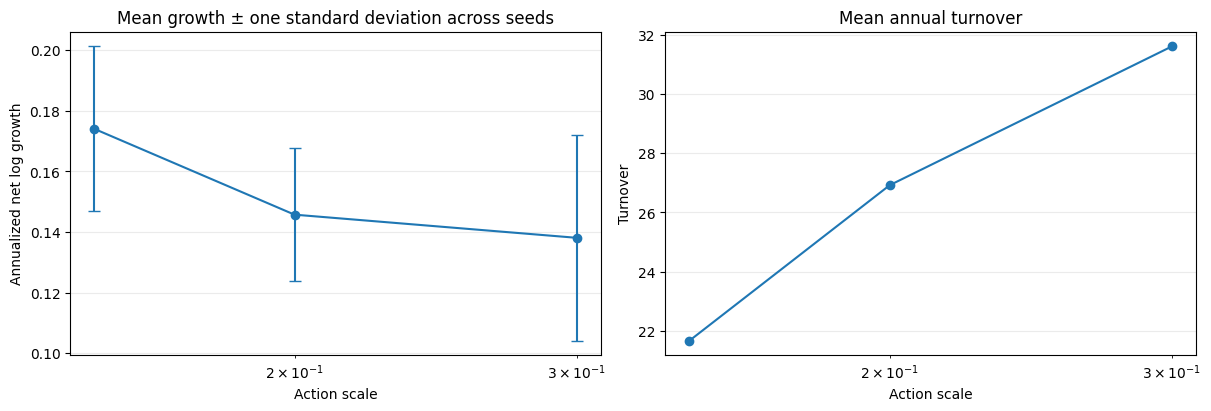

In [13]:
plot_summary = grid_summary.sort_index()
figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].errorbar(
    plot_summary.index,
    plot_summary["mean_net_log_growth"],
    yerr=plot_summary["std_net_log_growth"],
    fmt="o-", capsize=4,
)
axes[0].set_title("Mean growth ± one standard deviation across seeds")
axes[0].set_ylabel("Annualized net log growth")
plot_summary["mean_turnover"].plot(ax=axes[1], marker="o")
axes[1].set_title("Mean annual turnover")
axes[1].set_ylabel("Turnover")
for axis in axes:
    axis.set_xscale("log")
    axis.set_xlabel("Action scale")
    axis.grid(alpha=0.25)
plt.show()